In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

import matplotlib as mpl

from scipy import interpolate
import scipy.optimize

from copy import deepcopy
import time
from tqdm import tqdm

from ngsolve import *
from ngsolve.webgui import Draw
from netgen.csg import *

from netgen.occ import *
from netgen.meshing import IdentificationType

# my functions
from helper_functions import *
from dipole_poisson_solver import dipole_poisson_solver

In [2]:
### unit-system: Angstrom = 1, eV = 1, e_charge = 1

### choices, see lammps metal system: https://docs.lammps.org/units.html

Angstrom = 1
eV = 1
e_charge = 1
Volt = 1

### independent

finestructure_constant = 0.0072973525643 # Finestructure constant, independent of unit-system   , https://en.wikipedia.org/wiki/Fine-structure_constant

### derived

hbar = 6.582119569 * pow(10.0, -4.0) ## eV * pico seconds, 1 pico second = 10^(-12) seconds

### units of time are in pico seconds, this implies units of velocity are in Angstrom / picoseconds

c_speed_of_light = 2.99792458 * pow(10.0, 6.0) ## Angstrom/pico seconds

pico_second = 1

nm = 10 ## 1nm = 10 Angstrom


hbar_times_c = 1973  # eV * Angstrom  # https://en.wikipedia.org/wiki/Planck_constant#Reduced_Planck_constant
h_times_c = 2.0 * np.pi * hbar_times_c

epsilon_0 = (e_charge * e_charge) / (2.0 * finestructure_constant * h_times_c)    # https://en.wikipedia.org/wiki/Vacuum_permittivity
mu_0 = 1.0 / (c_speed_of_light * epsilon_0)    # https://en.wikipedia.org/wiki/Vacuum_permeability
mu_0 /= c_speed_of_light ### don't divide by c^2 immediately

######################
######################
######################


### constants
a_lattice = 2.46

grapheneheight = 3.35 # Angstrom

blg_grapheneheight = grapheneheight ### see Jung & MacDonald PRB 89, 035405 (2014) #2.0 * grapheneheight

bilayer_graphene_area, bilayer_graphene_volume = blg_area_vol(a_lattice, blg_grapheneheight, Angstrom)
print(blg_grapheneheight)

3.35


In [3]:
# eps tensor
inplane_hBn_bulk = 4.98 ### see https://www.nature.com/articles/s41699-018-0050-x 
outofplane_hBn_bulk = 3.03

inplane_graphene = 1.8 ### https://pubs.acs.org/doi/10.1021/nl303611v
outofplane_graphene = 3

In [4]:
dummy_idos_shape = np.zeros(2, np.int64)


dos_folder = "new_ps_helper_functions/JungMacDonald_energy_range_m200meV_200meV_increment_0.5meV_U_range_0_200_meV_increment_0.5meV_VSC"

#dos_folder = "new_ps_helper_functions/JungMacDonald_energy_range_m200meV_200meV_increment_0.25meV_U_range_0_200_meV_increment_0.25meV_VSC"




### read arrays

idos = np.load(dos_folder+"/idos_blg.npy")
    
band_gaps = np.load(dos_folder+"/band_gap.npy")

displacement_field_intervals = np.load(dos_folder+"/displacementfield_intervalls.npy")

energy_interval = np.load(dos_folder+"/energy_intervall.npy")

### shapes


#dummy_idos_shape = read_idos.shape

In [5]:
correct_prefactor = 1.0 / (bilayer_graphene_volume) ### this dos is already in units of 1/Energy, convert to density/Energy

idos = -idos * correct_prefactor


en_min = energy_interval[0] ## -0.2 eV
en_max = energy_interval[-1]  ## 0.2 eV

pot_min = displacement_field_intervals[0]  ## 0 eV
pot_max = displacement_field_intervals[-1] ## 0.2 eV


en_steps = idos.shape[1] 

e_incr = (en_max - en_min) / (en_steps - 1)

pot_steps = idos.shape[0] 

pot_incr = (pot_max - pot_min) / (pot_steps - 1)

en_intervall = np.linspace(en_min, en_max, en_steps)

en_incr = (en_max - en_min) / (en_steps - 1)

pot_intervall = np.linspace(pot_min, pot_max, pot_steps)

en_mesh, pot_mesh = np.meshgrid(en_intervall, pot_intervall)  # 2D grid for interpolation

begin_barycentricscipy_interpolation_time = time.time()

idos_interpolated = scipy.interpolate.LinearNDInterpolator(np.array([np.ravel(pot_mesh), np.ravel(en_mesh)]).T,
                                                           idos.reshape(pot_steps*en_steps))

end_barycentricscipy_interpolation_time = time.time()


print("interpolation took ", end_barycentricscipy_interpolation_time - begin_barycentricscipy_interpolation_time, " seconds")

interpolation took  6.060910701751709  seconds


In [6]:
# parameters
vac_box_width = 250
height_bottom = 2 * nm#blg_grapheneheight * 2.5 # 20 nm is 200 Angstrom, almost as high as the box is wide
height_top = 2 * nm#blg_grapheneheight * 2.5
dipole_moment_debye = 80

sphere_radius = 3 # 3
benzen_a = 1.4 # Angstrom
benzen_diameter = 2 * benzen_a
dipole_position = 0.02 * vac_box_width # basically 0


dipole_d = 3 * benzen_diameter 

number_backgates = 10
back_gates = np.linspace(-0.2, 0.2, number_backgates)
max_h = vac_box_width/10 #vac_box_width/15

fem_n = 300
epsilon_z = 1e-4
print('simulation dimensions in Angstrom: ')
print('hBb thickness: ', height_bottom)
print('blg thichness: ', blg_grapheneheight)
print('box width: ', vac_box_width)
print('dipole d: ', dipole_d)
print('dipole height over hBn: ', dipole_position)
print('dipole sphere radius: ', sphere_radius)

simulation dimensions in Angstrom: 
hBb thickness:  20
blg thichness:  3.35
box width:  250
dipole d:  8.399999999999999
dipole height over hBn:  5.0
dipole sphere radius:  3


In [7]:
# create solver
solver = dipole_poisson_solver(dipole_moment_debye, dipole_d, dipole_position, inplane_hBn_bulk, outofplane_hBn_bulk, inplane_graphene, outofplane_graphene, epsilon_0)
solver.build_geometry(vac_box_width, height_bottom, height_top, blg_grapheneheight, sphere_radius, max_h)

In [8]:
total_charges = []
total_charges_squared = []
iterations = []
ds = []
seps = []
Q_tops = []
Q_bots = []
ps = []
sep_inds = []

for V in back_gates:
    print(f'current back gate voltage: {V}')
    print(f'last: {back_gates[-1]}')
    solver.solve_without_BLG(V)
    solver.solve(fem_n, epsilon_z, idos_interpolated, pot_min, pot_max, en_min, en_max, use_abs=True, starting_alpha=0.01)

    total_charges.append(solver.total_charge)
    total_charges_squared.append(solver.total_charge_squared)
    iterations.append(solver.global_it[0])
    ds.append(solver.d_vec)
    seps.append(solver.separation)
    Q_tops.append(solver.Q_top)
    Q_bots.append(solver.Q_bot)
    ps.append(solver.p_total)
    sep_inds.append(solver.sep_index)

current back gate voltage: -0.2
last: 0.2
current back gate voltage: -0.15555555555555556
last: 0.2
current back gate voltage: -0.11111111111111112
last: 0.2
current back gate voltage: -0.06666666666666668
last: 0.2
current back gate voltage: -0.022222222222222227
last: 0.2
current back gate voltage: 0.022222222222222227
last: 0.2
current back gate voltage: 0.06666666666666665
last: 0.2
current back gate voltage: 0.1111111111111111
last: 0.2
current back gate voltage: 0.15555555555555556
last: 0.2
current back gate voltage: 0.2
last: 0.2


Text(0, 0.5, '$d \\: [\\AA]$')

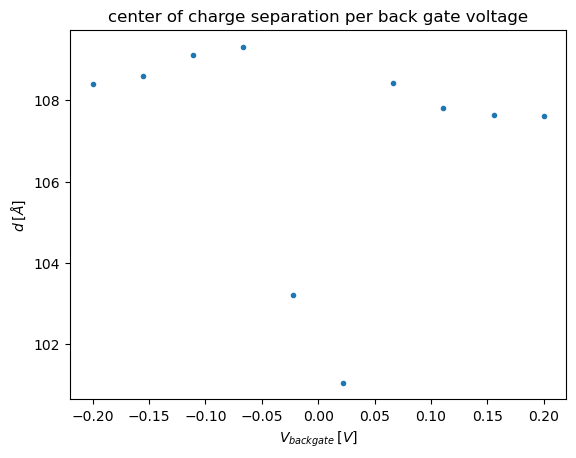

In [9]:
plt.plot(back_gates, seps, '.')
plt.title('center of charge separation per back gate voltage')
plt.xlabel('$V_{{backgate}} \\: [V]$')
plt.ylabel('$d \\: [\\AA]$')

In [23]:
max_sep = np.max(seps)
max_sep_v = back_gates[np.argmax(seps)]
min_sep = np.min(seps)
min_sep_v = back_gates[np.argmin(seps)]

print('maximum separation of ', max_sep, ' Angstrom at ', max_sep_v, ' V')
print('minimum separation of ', min_sep, ' Angstrom at ', min_sep_v, ' V')

maximum separation of  110.08839604748859  Angstrom at  0.04060150375939847  V
minimum separation of  71.499697005125  Angstrom at  0.000501253132832058  V


Text(0, 0.5, '$Q[e]$')

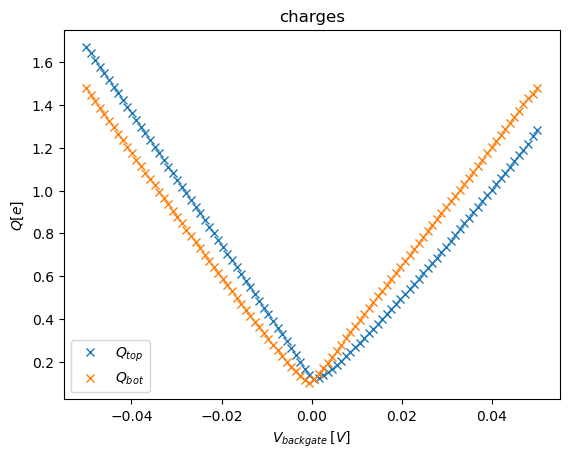

In [25]:
plt.plot(back_gates, Q_tops, 'x', label='$Q_{top}$')
plt.plot(back_gates, Q_bots, 'x', label='$Q_{bot}$')
plt.title('charges')
plt.legend()
plt.xlabel('$V_{{backgate}} \\: [V]$')
plt.ylabel('$Q[e]$')

In [26]:
print(back_gates[np.argmin(Q_bots)])

-0.0005050505050505083


In [27]:
print(back_gates[np.argmin(Q_tops)])

0.0005050505050505014


In [13]:
dipole_moments = np.array(ps)

print(dipole_moments.shape)
dipole_moments = np.linalg.norm(dipole_moments, axis=1)
print(dipole_moments.shape)

(100, 2)
(100,)


Text(0.5, 1.0, 'induced dipole moment per area')

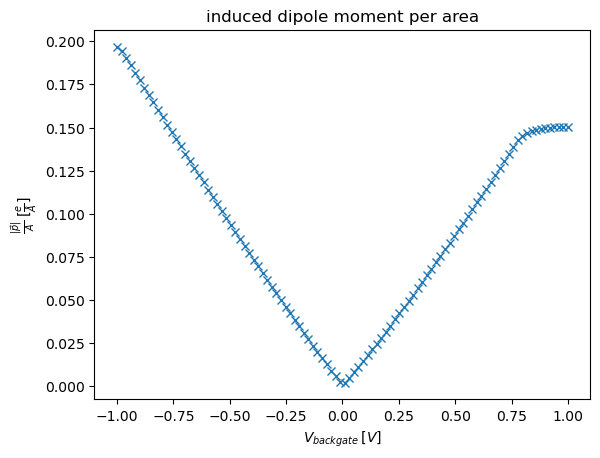

In [14]:
plt.plot(back_gates, dipole_moments/(solver.vac_box_width * solver.vac_box_width), 'x')
plt.xlabel('$V_{{backgate}} \\: [V]$')
plt.ylabel('$\\frac{|\\vec{{p}}|}{A} \\: [\\frac{e}{\\AA}]$')
plt.title('induced dipole moment per area')